### TS_1

In [ ]:
import pandas as pd
import kagglehub
from kagglehub import KaggleDatasetAdapter

#file_path = "https://www.kaggle.com/datasets/shenba/time-series-datasets?select=daily-minimum-temperatures-in-me.csv"
temperatures = kagglehub.load_dataset(KaggleDatasetAdapter.PANDAS,"shenba/time-series-datasets","daily-minimum-temperatures-in-me.csv")
temperatures.head()

/tmp/ipykernel_1476/1327662956.py:6: DeprecationWarning: Use dataset_load() instead of load_dataset(). load_dataset() will be removed in a future version.
  temperatures = kagglehub.load_dataset(KaggleDatasetAdapter.PANDAS,"shenba/time-series-datasets","daily-minimum-temperatures-in-me.csv")


100%|██████████| 54.5k/54.5k [00:00<00:00, 43.6MB/s]


,Date,Daily minimum temperatures
0,1/1/1981,20.7
1,1/2/1981,17.9
2,1/3/1981,18.8
3,1/4/1981,14.6
4,1/5/1981,15.8


In [ ]:
temperatures["Date"] = pd.to_datetime(temperatures["Date"], format="%m/%d/%Y")
temperatures["Daily minimum temperatures"] = pd.to_numeric(temperatures["Daily minimum temperatures"], errors="coerce")
temperatures.dtypes

,0
Date,datetime64[ns]
Daily minimum temperatures,float64


In [ ]:
#отсортировать,  проверить дубликаты, установить временной индекс
temperatures.sort_values("Date").drop_duplicates("Date").set_index("Date")

,Daily minimum temperatures
Date,
1981-01-01,20.7
1981-01-02,17.9
1981-01-03,18.8
1981-01-04,14.6
1981-01-05,15.8
...,...
1990-12-27,14
1990-12-28,13.6
1990-12-29,13.5


##### Проанализировать пропуски. Проверить частоту через date_range

In [ ]:
dates = pd.to_datetime(temperatures["Date"])

full_dates = pd.date_range(dates.min(), dates.max(), freq="D")
missing_dates = full_dates.difference(pd.DatetimeIndex(dates))

print("Missing dates:", missing_dates)
print("Number missing:", len(missing_dates))

Missing dates: DatetimeIndex(['1984-12-31', '1988-12-31'], dtype='datetime64[ns]', freq=None)
Number missing: 2


#### Построить графики
- весь ряд;
- увеличенные фрагменты.

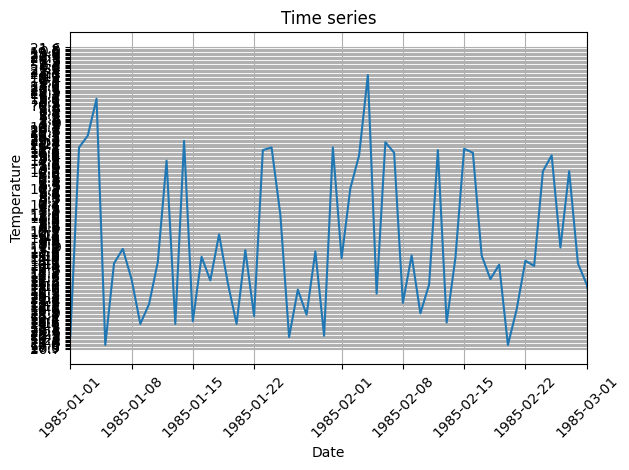

In [ ]:
import matplotlib.pyplot as plt

plt.plot(dates,temperatures['Daily minimum temperatures'])
plt.xlabel("Date")
plt.ylabel("Temperature")
plt.title("Time series")
plt.grid(True)
# Показать только выбранный период
plt.xlim(pd.Timestamp('1985-01-01'), pd.Timestamp('1985-03-01'))

plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

Скользящее среднее и скользящее стандартное отклонение


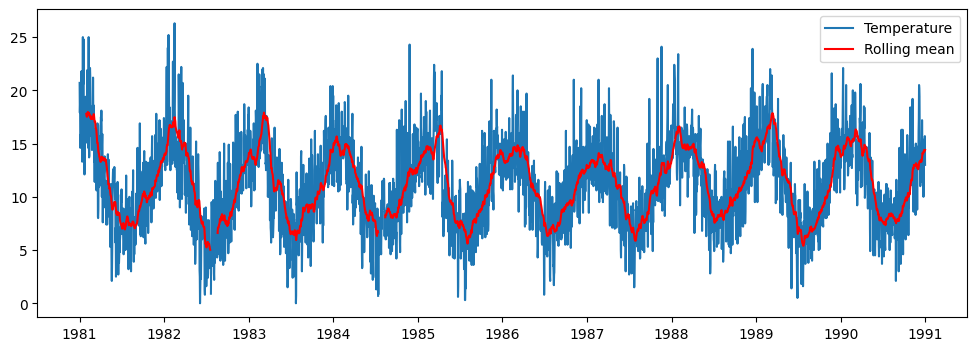

In [ ]:
temperatures["rolling_mean"] = temperatures['Daily minimum temperatures'].rolling(30).mean()
temperatures["rolling_std"] = temperatures['Daily minimum temperatures'].rolling(30).std()

plt.figure(figsize=(12, 4))
plt.plot(dates, temperatures["Daily minimum temperatures"], label="Temperature")
plt.plot(dates, temperatures["rolling_mean"], label="Rolling mean", color="red")
plt.legend()
plt.show()



Сезонные подсерии

В каждой подсерии точки показывают среднюю минимальную температуру за месяц конкретного года, а красная линия — среднее этих значений за все годы.

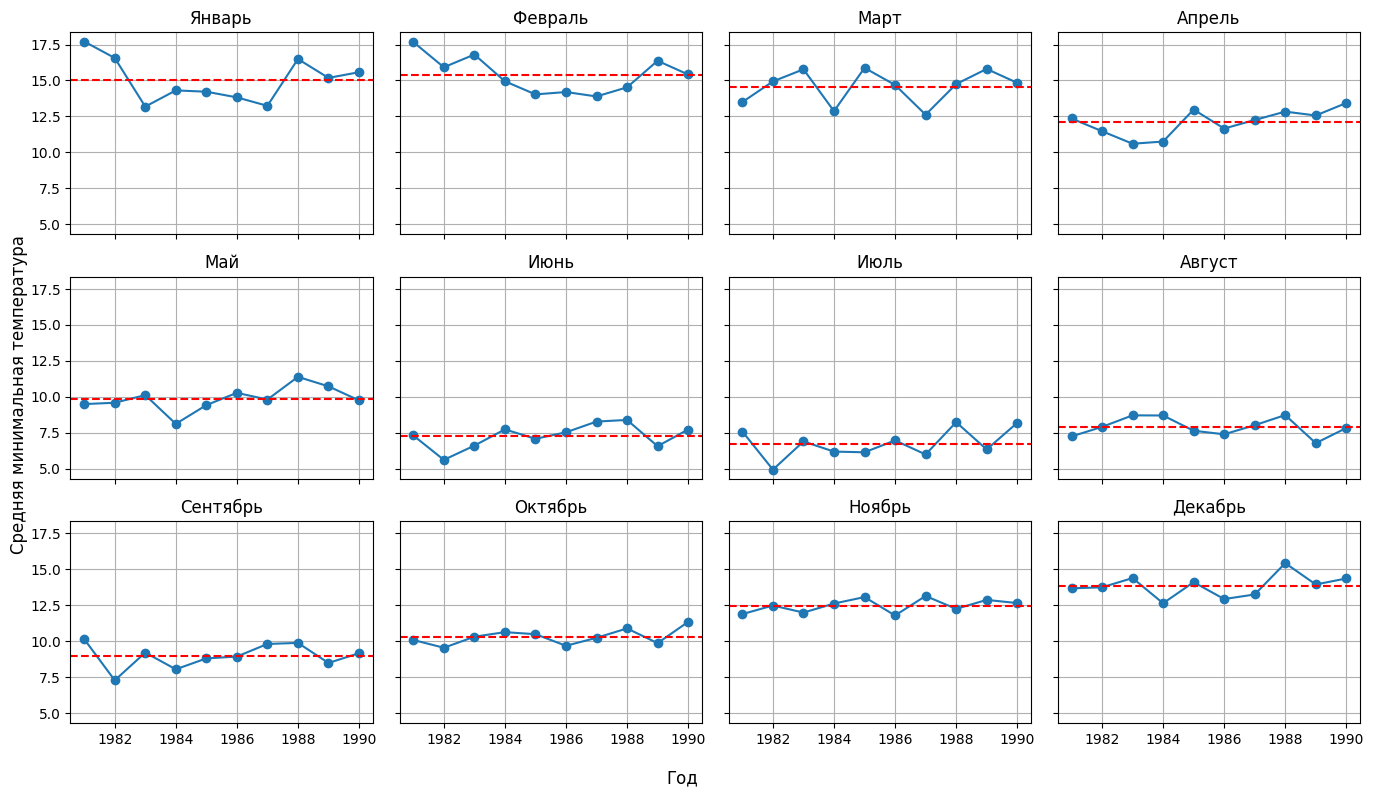

In [ ]:
# Средняя температура за каждый месяц каждого года
monthly = temperatures.groupby([
    temperatures["Date"].dt.year.rename("year"),
    temperatures["Date"].dt.month.rename("month")
])['Daily minimum temperatures'].mean().unstack("month") #unstack("month") превращает месяцы в столбцы

fig, axes = plt.subplots(3, 4, figsize=(14, 8), sharex=True, sharey=True)

months = [
    "Январь", "Февраль", "Март", "Апрель",
    "Май", "Июнь", "Июль", "Август",
    "Сентябрь", "Октябрь", "Ноябрь", "Декабрь"
]

for month, ax in enumerate(axes.flat, start=1):
    if month in monthly.columns:
        ax.plot(monthly.index, monthly[month], marker="o")
        ax.axhline(monthly[month].mean(), color="red", linestyle="--")

    ax.set_title(months[month - 1])
    ax.grid(True)

fig.supxlabel("Год")
fig.supylabel("Средняя минимальная температура")
plt.tight_layout()
plt.show()